<center><h1>Blombach_George_HW6</h1></center>

Name: George Blombach | Github Username: gblombach | USC ID: 2416-0961-99

## 1. Tree-Based Methods

Import packages

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [2]:
test = pd.read_csv('../data/aps_failure_test_set.csv', skiprows=20, header=0, na_values='na')
train = pd.read_csv('../data/aps_failure_training_set.csv', skiprows=20, header=0, na_values='na')
#test.head() #train.head()

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

**sklearn** provides three types of classes for imputation: SimpleImputer, KNNImputer, and IterativeImputer. The SimpleImputer class supports mean, median, most_frequent, and constant techniques. Reference https://scikit-learn.org/1.8/auto_examples/impute/plot_missing_values.html. For this assignment I will use **median imputation** because it is simple and it does not discard otherwise useful observations.

In [3]:
X_train = train.drop(columns="class").copy()                      #separate values before imputation
y_train = train["class"].copy()
X_test = test.drop(columns="class").copy()
y_test = test["class"].copy()
imputer = SimpleImputer(strategy="median")                        #setup imputer
#impute and preserve feature names; NOTE imputer learns the medians from X_train and applies those same medians to X_test
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)
display(X_train_imputed.head(3))

,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,76698.0,0.0,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,33058.0,0.0,0.000000e+00,126.0,0.0,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,41040.0,0.0,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0


#### (ii) Calculate the coefficient of variation

In [4]:
#calculate the coefficient of variation $CV = s/m,where s is sample standard deviation and m is sample mean.
cv = X_train_imputed.std(ddof=1) / X_train_imputed.mean()
display(cv.head(3))

aa_000     2.450938
ab_000    10.383494
ac_000     2.310241
dtype: float64

#### (iii) Plot a correlation matrix

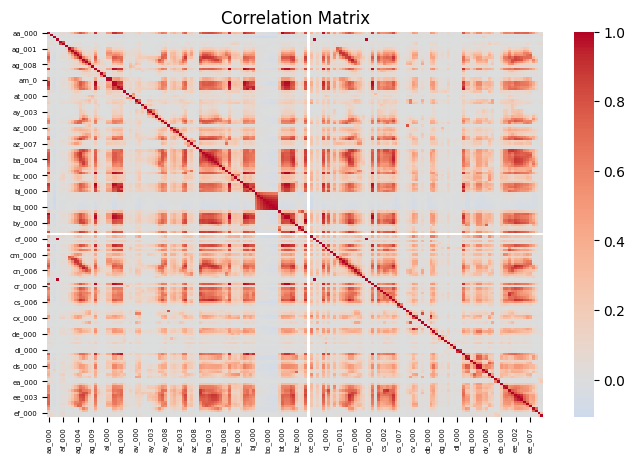

In [5]:
correlation = X_train_imputed.corr()                   # Calculate the pairwise correlation coefficients using the imputed training predictors
plt.figure(figsize=(8, 5))                             # Create the figure for the correlation heatmap
sns.heatmap(correlation, cmap="coolwarm", center=0)    # Plot the correlation matrix
plt.xticks(fontsize=5)                                 # Reduce tick-label size because the dataset contains many predictors
plt.yticks(fontsize=5)
plt.title("Correlation Matrix")                        # Add title
plt.show()

#### (iv) Make scatter plots and box plots

$\lfloor\sqrt{170}\rceil = 13$

In [6]:
top_13 = cv.nlargest(13).index                              # get top 13 
#print(top_13)
plot_data = X_train_imputed[top_13].copy()
plot_data['class'] = y_train.values

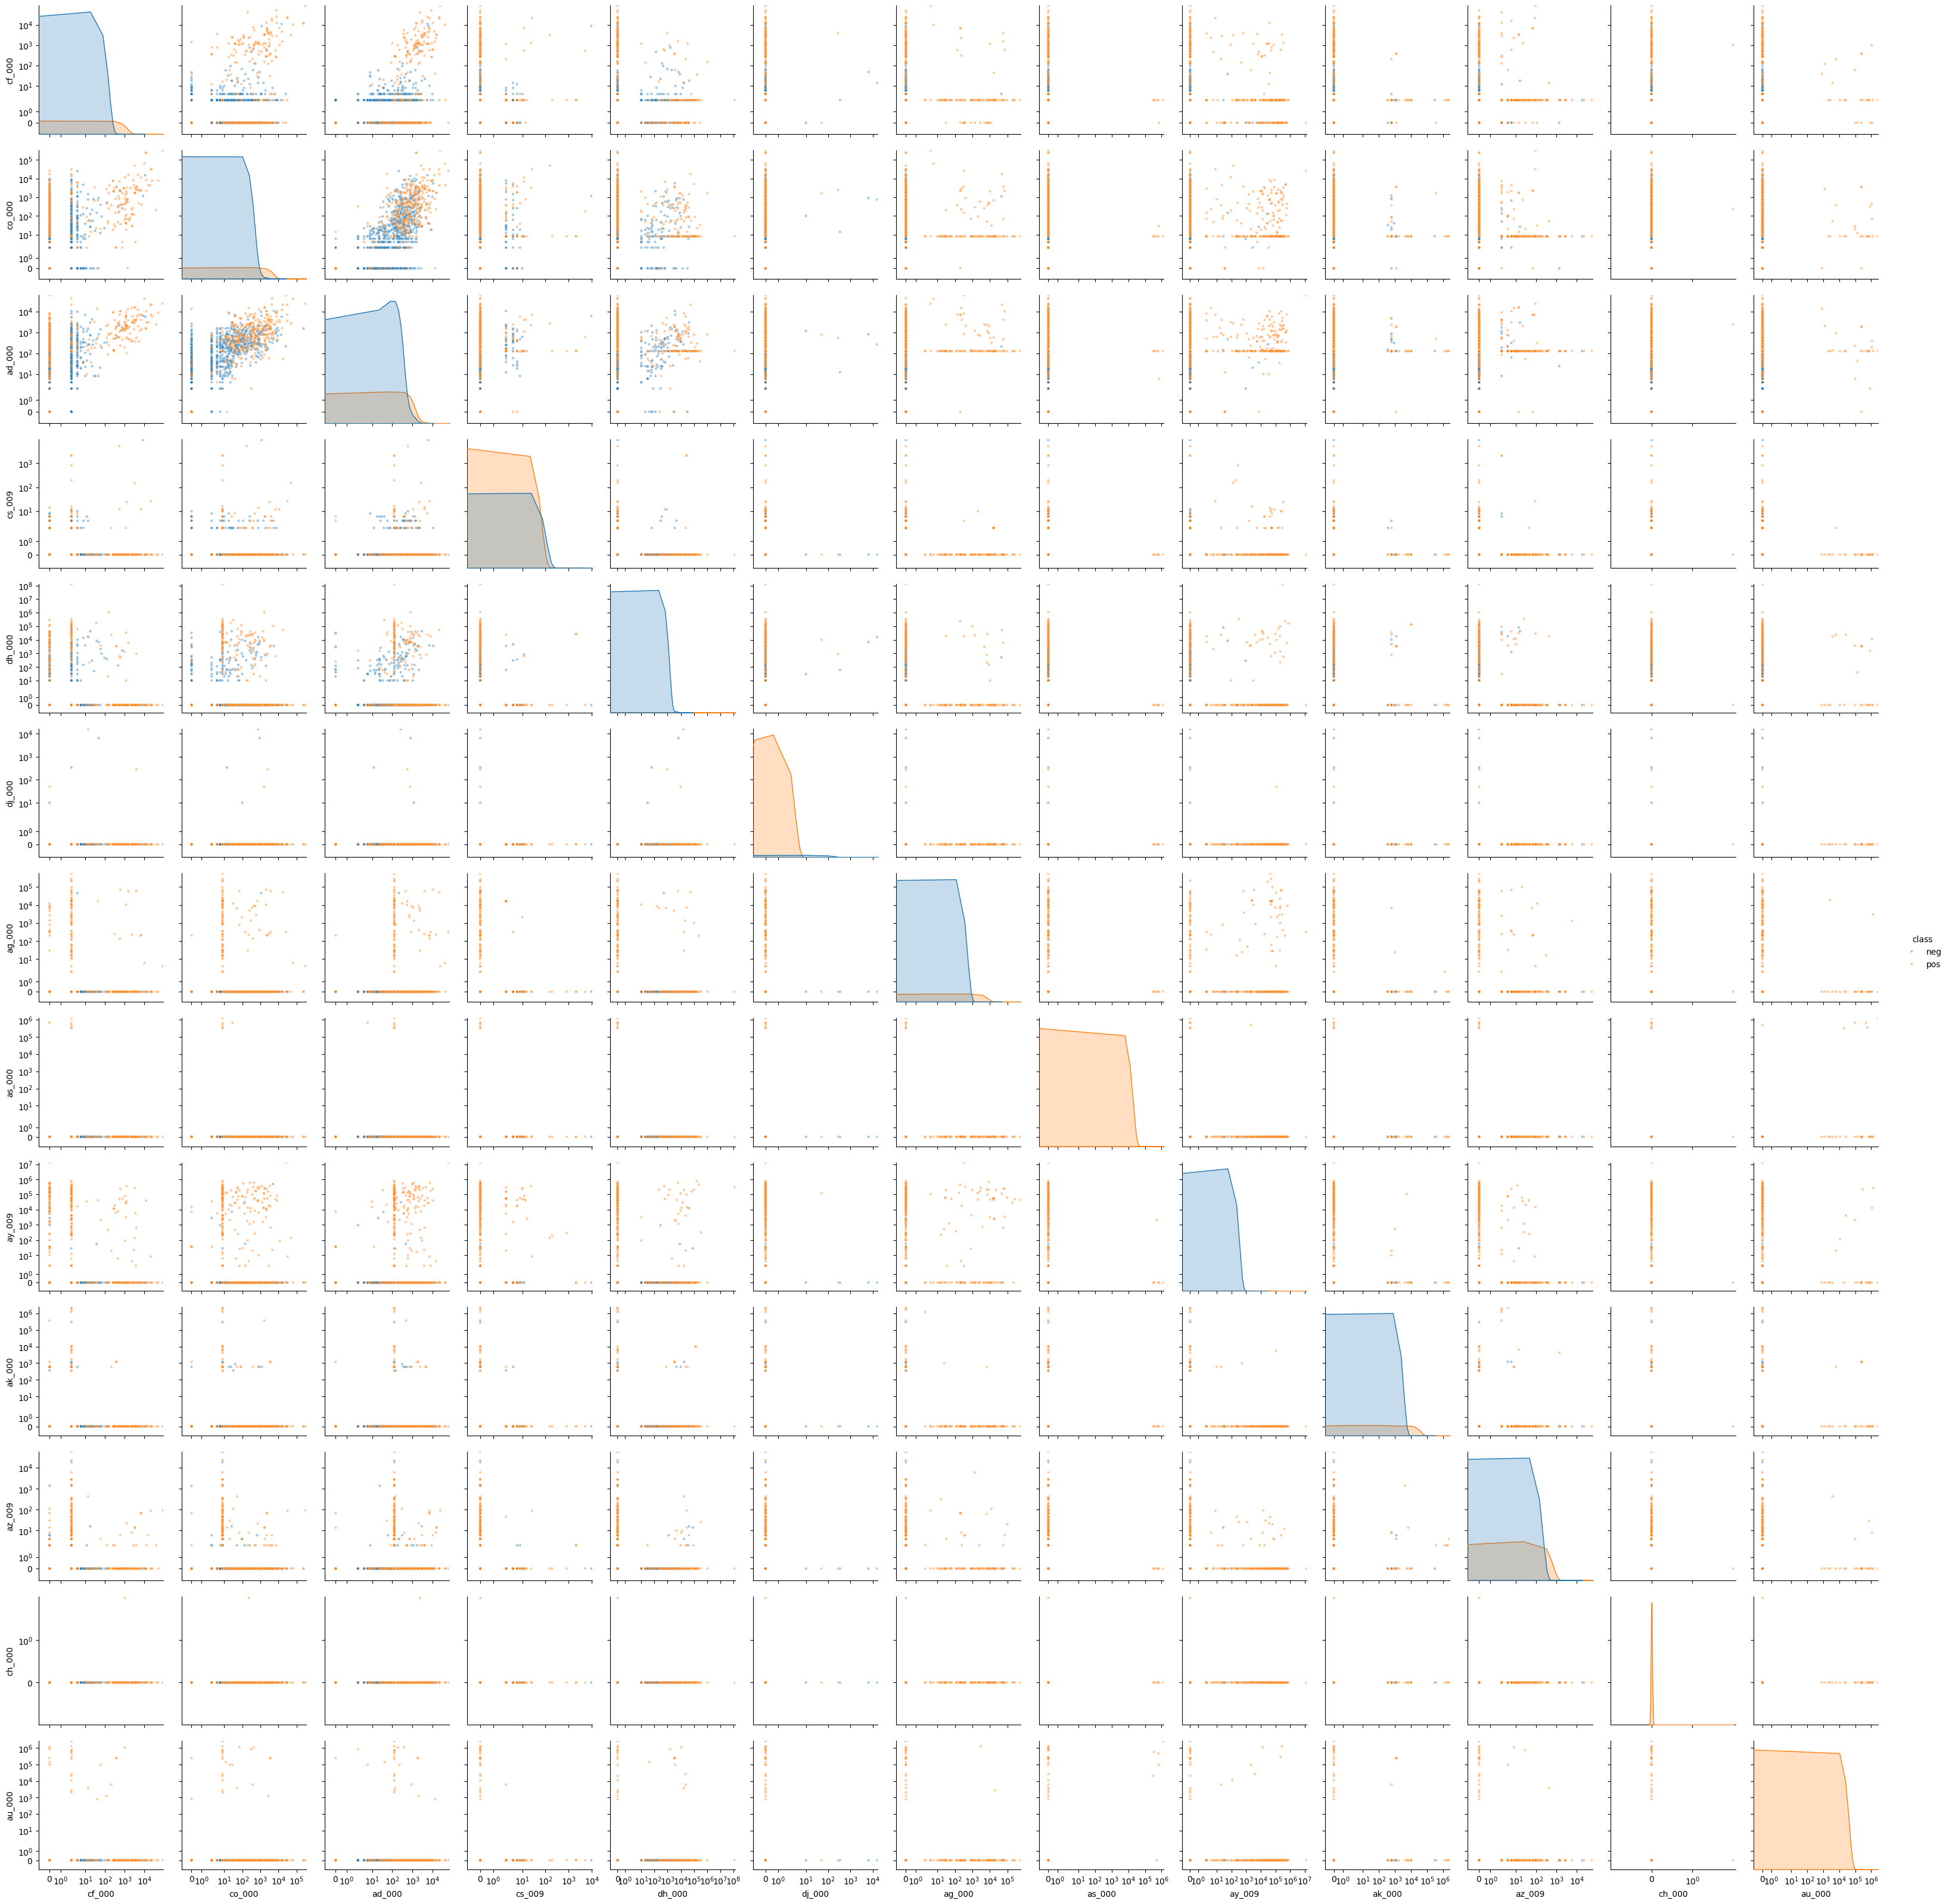

In [7]:
neg = plot_data[plot_data["class"] == "neg"].sample(1000, random_state=333)         # Sample the data for visualization only
pos = plot_data[plot_data["class"] == "pos"]                                        # keep all 1000 positives
scatter_data = pd.concat([neg, pos])                                                # combine
pairplot = sns.pairplot(scatter_data, vars=top_13, hue="class", plot_kws={"alpha": 0.4, "s": 10})
pairplot.set(xscale="symlog", yscale="symlog", ylim=-1, xlim=-1)                    #switch to symlog scale because of data ranges and zero values
plt.show()

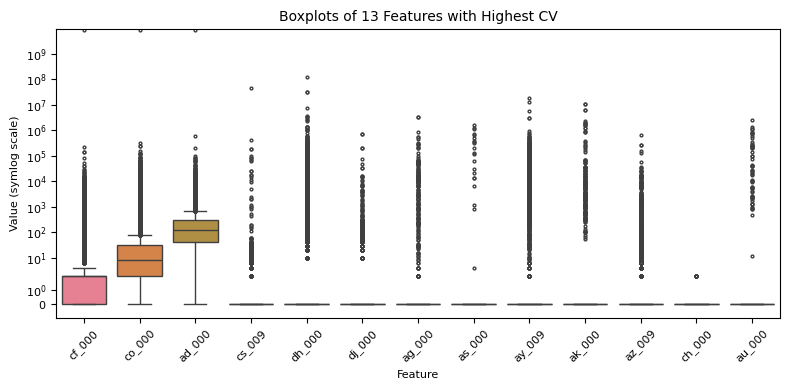

In [8]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=X_train_imputed[top_13], flierprops={'markersize': 2})
plt.yscale("symlog")                                                      #change to log scale for readability
plt.xticks(rotation=45, fontsize=8)
plt.yticks(fontsize=8)
plt.xlabel("Feature", fontsize=8)
plt.ylabel("Value (symlog scale)", fontsize=8)
plt.title("Boxplots of 13 Features with Highest CV", fontsize=10)
plt.ylim(bottom=-1)                                                       #show the zeros
plt.tight_layout()
plt.show()

**Observations:** 1) visual patterns are not tests of statistical significance. 2) these 13 features were selected because they have the highest coefficient of variation, not because they have the strongest relationship with the response

No conclusions about the statistical significance of the features can be made from the scatter plots alone. The plots can reveal possible relationships, correlations, and outliers, but statistical significance would require further statistical analysis. The 13 features were selected based on their coefficients of variation only for visualization and will not be the only features used in subsequent analysis.

#### (v) Is this data set imbalanced?

In [9]:
y_train.value_counts()                              #Determine the number of positive and negative data

class
neg    59000
pos     1000
Name: count, dtype: int64

Yes, this data is highly imbalanced (59:1 ratio).

### (c) Train a random forest

In [10]:
# Function to evaluate models for this question and others
# Returns results : dict Predictions, probabilities, confusion matrices, errors, AUC values, OOB error, and CV error.
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name="Model", cv_error=None):
    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    # Probabilities for positive class
    positive_class_index = list(model.classes_).index(1)
    y_train_prob = model.predict_proba(X_train)[:, positive_class_index]
    y_test_prob = model.predict_proba(X_test)[:, positive_class_index]
    cm_train = confusion_matrix(y_train, y_train_pred, labels=[0, 1])       # Confusion matrices
    cm_test = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
    cm_display = pd.DataFrame({"Train - Pred Neg": cm_train[:, 0], "Train - Pred Pos": cm_train[:, 1], "Test - Pred Neg": cm_test[:, 0], "Test - Pred Pos": cm_test[:, 1]}, 
                              index=["Actual Neg", "Actual Pos"])
    train_error = np.mean(y_train_pred != y_train)                          # Misclassification errors
    test_error = np.mean(y_test_pred != y_test)
    train_auc = roc_auc_score(y_train, y_train_prob)                        # AUC
    test_auc = roc_auc_score(y_test, y_test_prob)
    oob_error = None                                                        # Use OOB if supported
    if hasattr(model, "oob_score_"):
        oob_error = 1 - model.oob_score_
    # Summary table
    summary = pd.DataFrame({"Metric": ["Misclassification Error","AUC", ], "Training": [train_error, train_auc], "Test": [ test_error, test_auc]})
    print(model_name, "=" * len(model_name), "\nConfusion Matrices:")
    display(cm_display)
    print("\nPerformance:")
    display(summary.round(6))
    if cv_error is not None:
        print(f"Cross-Validation Error: {cv_error:.6f}", "Absolute CV-Test Difference:",f"{abs(cv_error - test_error):.6f}")
    if oob_error is not None:
        print(f"OOB Error Estimate: {oob_error:.6f}", "Absolute OOB-Test Difference: ", f"{abs(oob_error - test_error):.6f}")
    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)              # ROC curve graph
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
    plt.figure(figsize=(2, 2))
    plt.plot(fpr_train, tpr_train, linewidth=2, label=f"Training ROC (AUC = {train_auc:.4f})")
    plt.plot(fpr_test, tpr_test, linewidth=2, label=f"Test ROC (AUC = {test_auc:.4f})")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier")
    plt.xlabel("False Positive Rate", fontsize=8)
    plt.ylabel("True Positive Rate", fontsize=8)
    plt.title(f"{model_name} ROC Curves", fontsize=10)
    plt.tick_params(axis='both', labelsize=6)
    plt.legend(fontsize=6)
    plt.show()
    # Return all results for later comparisons
    return {"model_name": model_name, "model": model, "train_predictions": y_train_pred, "test_predictions": y_test_pred, "train_probabilities": y_train_prob, "test_probabilities": y_test_prob,
            "train_confusion_matrix": cm_train,"test_confusion_matrix": cm_test, "train_error": train_error, "test_error": test_error, "train_auc": train_auc, "test_auc": test_auc, "cv_error": cv_error,
            "oob_error": oob_error}

Uncompensated Random Forest =========================== 
Confusion Matrices:


,Train - Pred Neg,Train - Pred Pos,Test - Pred Neg,Test - Pred Pos
Actual Neg,59000,0,15609,16
Actual Pos,0,1000,107,268



Performance:


,Metric,Training,Test
0,Misclassification Error,0.0,0.007688
1,AUC,1.0,0.994366


OOB Error Estimate: 0.005967 Absolute OOB-Test Difference:  0.001721


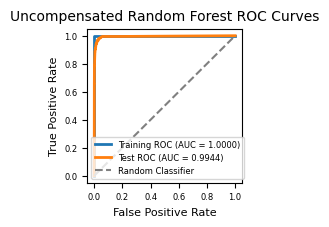

In [11]:
y_train_binary = y_train.map({"neg": 0, "pos": 1})                  #setup training and testing for binary evaluation
y_test_binary = y_test.map({"neg": 0, "pos": 1})
# train the random forest
random_forest = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=333, n_jobs=-1)
random_forest.fit(X_train_imputed, y_train_binary)
# call function Uncompensated Random Forest
random_forest_results = evaluate_model(model=random_forest, X_train=X_train_imputed, y_train=y_train_binary, X_test=X_test_imputed, y_test=y_test_binary, model_name="Uncompensated Random Forest")

##### Assessment

The random forest achieved a training misclassification error of 0 and a test misclassification error of 0.007688. The training and test AUCs were 1.0000 and 0.994366, respectively. The out-of-bag error estimate was 0.005967, which is close to the test error of 0.007688. Thus, the OOB error provides a reasonably similar estimate of the model's test misclassification error. The perfect training performance also indicates that the random forest fits the training data extremely closely.

### (d) Research class imbalance in random forest

A standard way to address class imbalance in a random forest is class weighting. Scikit-learn provides the class_weight="balanced_subsample" option so class weights are recalculated from each tree’s bootstrap sample. Random forests build trees from bootstrap subsamples, and class_weight is an available classifier parameter.

Weighted Class Random Forest ============================ 
Confusion Matrices:


,Train - Pred Neg,Train - Pred Pos,Test - Pred Neg,Test - Pred Pos
Actual Neg,59000,0,15610,15
Actual Pos,0,1000,159,216



Performance:


,Metric,Training,Test
0,Misclassification Error,0.0,0.010875
1,AUC,1.0,0.993362


OOB Error Estimate: 0.007483 Absolute OOB-Test Difference:  0.003392


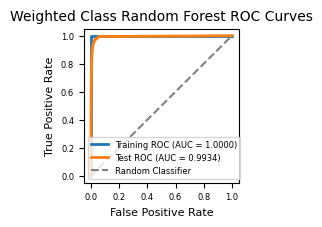

In [12]:
# create balanced random forest
balanced_random_forest = RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample", oob_score=True, random_state=333,n_jobs=-1)
balanced_random_forest.fit(X_train_imputed, y_train_binary)
#call evaluation function
balanced_random_forest_results = evaluate_model(model=balanced_random_forest, X_train=X_train_imputed, y_train=y_train_binary, X_test=X_test_imputed, y_test=y_test_binary, model_name="Weighted Class Random Forest")

In [13]:
print("COMPARISON:\n")
#int(random_forest_results["test_error"])
comparison = pd.DataFrame({"Metric": ["Training Misclassification Error", "Test Misclassification Error", "Training AUC", "Test AUC", "OOB Error"],
    "Uncompensated RF": [random_forest_results["train_error"], random_forest_results["test_error"], random_forest_results["train_auc"], random_forest_results["test_auc"], random_forest_results["oob_error"]],
    "Balanced RF": [balanced_random_forest_results["train_error"], balanced_random_forest_results["test_error"], balanced_random_forest_results["train_auc"], balanced_random_forest_results["test_auc"], 
                    balanced_random_forest_results["oob_error"]]})
display(comparison.round(6))

COMPARISON:



,Metric,Uncompensated RF,Balanced RF
0,Training Misclassification Error,0.000000,0.000000
1,Test Misclassification Error,0.007688,0.010875
2,Training AUC,1.000000,1.000000
3,Test AUC,0.994366,0.993362
4,OOB Error,0.005967,0.007483


### (e) XGBoost and Model Trees

Uncompensated XGBoost ===================== 
Confusion Matrices:


,Train - Pred Neg,Train - Pred Pos,Test - Pred Neg,Test - Pred Pos
Actual Neg,59000,0,15610,15
Actual Pos,0,1000,80,295



Performance:


,Metric,Training,Test
0,Misclassification Error,0.0,0.005938
1,AUC,1.0,0.994926


Cross-Validation Error: 0.005450 Absolute CV-Test Difference: 0.000488


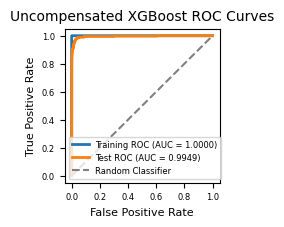

Selected alpha:  0.1
5-Fold CV F1: 0.821688
5-Fold CV Accuracy: 0.994550
5-Fold CV Error: 0.005450
Test Error: 0.005938


In [14]:
cv_folds_x = StratifiedKFold(n_splits=5, shuffle=True, random_state=333)      # define stratification
# create Uncompenstated XGBoost model, using Standard XGBoost with L1 regularization per Piazza post
xgb_base = XGBClassifier(objective="binary:logistic", eval_metric="logloss", n_estimators=500, learning_rate=0.1, max_depth=6, random_state=333, n_jobs=1)
alpha_grid = {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]}                 # select alpha using cross validation
# Use F1 to select reg_alpha while also recording accuracy to calculate the CV misclassification error
grid_search_x = GridSearchCV(estimator=xgb_base, param_grid=alpha_grid, scoring={"f1":"f1", "accuracy":"accuracy"}, cv=cv_folds_x, n_jobs=-1, return_train_score=True, refit="f1")
grid_search_x.fit(X_train_imputed, y_train_binary)
best_alpha_x = grid_search_x.best_params_["reg_alpha"]
best_index_x = grid_search_x.best_index_
cv_f1_x = grid_search_x.cv_results_["mean_test_f1"][best_index_x]             # F1 used to select alpha  
cv_accuracy_x = grid_search_x.cv_results_["mean_test_accuracy"][best_index_x] # Accuracy used to calculate CV misclassification error
cv_error_x = 1 - cv_accuracy_x
xgb_model = grid_search_x.best_estimator_                                     # get final fitted model with selected alpha
# Call evaluation function
xgb_results = evaluate_model(model=xgb_model, X_train=X_train_imputed, y_train=y_train_binary, X_test=X_test_imputed, y_test=y_test_binary, model_name="Uncompensated XGBoost", cv_error=cv_error_x)
print(f"Selected alpha:  {best_alpha_x}")
print(f"5-Fold CV F1: {cv_f1_x:.6f}")
print(f"5-Fold CV Accuracy: {cv_accuracy_x:.6f}")
print(f"5-Fold CV Error: {cv_error_x:.6f}")
print(f"Test Error: {xgb_results['test_error']:.6f}")

### (f) Use SMOTE to pre-process your data

NOTE: The crucial correction is to place SMOTE inside each cross-validation fold. Applying SMOTE before cross-validation leaks synthetic information across folds and gives an optimistic CV estimate.

Selected alpha: 0
5-Fold CV F1: 0.811731
5-Fold CV Accuracy: 0.993700
5-Fold CV Error: 0.006300
SMOTE XGBoost ============= 
Confusion Matrices:


,Train - Pred Neg,Train - Pred Pos,Test - Pred Neg,Test - Pred Pos
Actual Neg,59000,0,15589,36
Actual Pos,1,999,64,311



Performance:


,Metric,Training,Test
0,Misclassification Error,0.000017,0.006250
1,AUC,1.000000,0.994676


Cross-Validation Error: 0.006300 Absolute CV-Test Difference: 0.000050


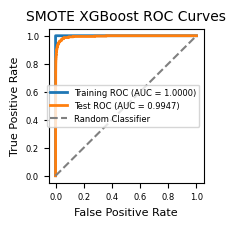

In [15]:
# use the correct cross-validation method is to put SMOTE inside an imblearn pipeline
smote_xgb_pipeline = Pipeline([("smote",SMOTE(random_state=333)),("xgb",XGBClassifier(objective="binary:logistic", eval_metric="logloss", n_estimators=500, learning_rate=0.1, max_depth=6,
                            random_state=333, n_jobs=1))])
# define alpha grid and train 
alpha_grid_smote = {"xgb__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]}
cv_folds_smote = StratifiedKFold(n_splits=5, shuffle=True, random_state=333)
# Use F1 to select reg_alpha while also recording accuracy to calculate the CV misclassification error
smote_xgb_grid = GridSearchCV(estimator=smote_xgb_pipeline, param_grid=alpha_grid_smote, scoring={"f1":"f1", "accuracy":"accuracy"}, cv=cv_folds_smote, n_jobs=-1, return_train_score=True, refit="f1")
smote_xgb_grid.fit(X_train_imputed, y_train_binary)
best_alpha_smote = smote_xgb_grid.best_params_["xgb__reg_alpha"]                        # show selected alpha and CV error
best_index_smote = smote_xgb_grid.best_index_
cv_f1_smote = smote_xgb_grid.cv_results_["mean_test_f1"][best_index_smote]
cv_accuracy_smote = smote_xgb_grid.cv_results_["mean_test_accuracy"][best_index_smote]
cv_error_smote = 1 - cv_accuracy_smote
print(f"Selected alpha: {best_alpha_smote}")
print(f"5-Fold CV F1: {cv_f1_smote:.6f}")
print(f"5-Fold CV Accuracy: {cv_accuracy_smote:.6f}")
print(f"5-Fold CV Error: {cv_error_smote:.6f}")
smote_xgb_model = smote_xgb_grid.best_estimator_                                       # get SMOTE fitted pipineline
smote_xgb_results = evaluate_model(model=smote_xgb_model, X_train=X_train_imputed,     # call evaulation function
                y_train=y_train_binary,  X_test=X_test_imputed, y_test=y_test_binary, model_name="SMOTE XGBoost", cv_error=cv_error_smote)

## 2. ISLR 6.6.3

NOTE: This is the constrained form of Lasso regression discussed on pp 243-245.

- (a) When $s = 0$ then all slope coefficients must be 0, too. As $s$ increases, the set of allowable coefficient values increases, so the training RSS cannot increase: **Training RSS Steadily Decreases**
- (b) Initially, when $s$ increases it reduces underfitting and lowers test RSS. However, too much flexibility can produce overfitting, and eventually it can cause Test RSS to increase: **Test RSS Decreases, then Increases**
- (c) When $s$ is small, the coefficients are strongly constrained, so the model is relatively insensitive to changes in the training data. As $s$ increases, the fitted coefficients become more flexible and variable: **Variance Steadily Increases**
- (d) When $s$ is small it forces coefficients toward zero, which produces higher bias. When $s$ increases it relaxes the constraint and allows the model to better approximate the underlying relationship: **Squared Bias Steadily Decreases**
- (e) An irreducible error comes from random noise in the data-generating process. It does not depend on $s$ or the flexibility of the fitted model: **Irreducible Error Remains Constant**
  


## 3. ISLR 6.6.5 (page 285)

**(a)** The ridge objective is: $\min_{\beta_1,\beta_2}\left[\sum_{i=1}^{2}\left(y_i-\beta_1 x_{i1}-\beta_2 x_{i2}\right)^2+\lambda\left(\beta_1^2+\beta_2^2\right)\right]$

Expanded, it can be written $\min_{\beta_1,\beta_2}\left[(y_1-\beta_1 x_{11}-\beta_2 x_{12})^2+(y_2-\beta_1 x_{21}-\beta_2 x_{22})^2+\lambda(\beta_1^2+\beta_2^2)\right]$

Since we know that $x_{i1}=x_{i2}$, it can be simplified to: $\boldsymbol{\min_{\beta_1,\beta_2}\left[\sum_{i=1}^{2}\left(y_i-(\beta_1 + \beta_2)x_{i1}\right)^2+\lambda\left(\beta_1^2+\beta_2^2\right)\right]}$

**(b)** The prediciton error depends on the sum of the coefficinets: $\beta_{1} + \beta_2$, but the ridge penalty is  $\beta_1^2+\beta_2^2$. For a fixed sum $\beta_1+\beta_2=s$, the penalty is minimized when the two coefficients are equal.

Using the identity $\beta_1^2+\beta_2^2=\frac{(\beta_1+\beta_2)^2+(\beta_1-\beta_2)^2}{2}$ the fixes sum $s$ becomes $\frac{s^2+(\beta_1-\beta_2)^2}{2}$

Therefore, the penalty is the smallest when $\beta_{1} - \beta_2 = 0$, therefore $\hat\beta_{1} = \hat\beta_2$

**(c)** The general Lasso approach is $\min_{\beta_1,\beta_2}\left\{\sum_{i=1}^{2}\left(y_i-\beta_1 x_{i1}-\beta_2 x_{i2}\right)^2+\lambda\left(|\beta_1|+|\beta_2|\right)\right\}$

Expanding out the observations, it can be written: $\min_{\beta_1,\beta_2}\left\{(y_1-\beta_1 x_{11}-\beta_2 x_{12})^2+(y_2-\beta_1 x_{21}-\beta_2 x_{22})^2+\lambda(|\beta_1|+|\beta_2|)\right\}$

Since $x_{11}=x_{12} = x, x_{21}=x_{22} = -x, y_1 = y, \text{and } y_2 = −y$, this becomes

$$\boldsymbol{\min_{\beta_1,\beta_2}\left\{2\left[y - x\left(\beta_1 + \beta_2\right)\right]^2 +\lambda(|\beta_1|+|\beta_2|)\right\}}$$


**(d)** Because the two predictors are identical, the prediction error depends only  on the sum of the coefficients: $s = \beta_1 + \beta_2$. So, RSS depends only on $s$: $2[y-xs]^2$.  Per the *traingle inequality rule*, $∣\beta_1∣+∣\beta_2∣\geq∣\beta_1 + \beta_2∣=∣s|$, which means the smallest Lasso penalty for a fixed value $s$ is $∣\beta_1∣ + ∣\beta_2∣=∣s∣$ when they have the same sign. Thus, the two-variable problem can be reduced to ${\min_{s}\left\{2\left(y - xs\right)^2 +\lambda(|s|)\right\}}$. 

Therefore, any nonnegative coefficients satisfying $\hat\beta_1 + \hat\beta_2 = \hat{s}$ (when $\hat{s} > 0$) produce the same RSS and the same Lasso penalty (eg. 0+5=5, 1+4=5, 2+3=5, etc.), so there are many ways that $\hat{s}$ can be distributed between the two coefficients, so the lasso coefficient estimates are not unique. The only exception is when the sum $\hat{s} = 0$, in which case the minimum-penalty solution is $\left(\hat\beta_1,\hat\beta_2\right)=(0,0)$

## 4. ISLR 8.4.5

Classes: Red, Green
$P$(Class is Red|X) Estimates: 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, and 0.75

**MAJORITY VOTE APPROACH**: Individual tree predictions are Red if $P(Red∣X)>0.5$ and Green if $P(Red∣X)<0.5$. So, Green = {0.1, 0.15, 0.2, .02} and Red = {0.55, 0.6, 0.6, 0.65, 0.7, 0.75}. Red has the majority of the values, 6 of 10, so the **Majority Vote is Red**.
  
**AVERAGE PROBABILITY**: Get the average value: $\frac{0.1 + 0.15 + 0.2 + .02 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75}{10} = .45$. Since $0.45 < 0.50$, the prediction is Green. **Average Probabilty is Green**

NOTE: Majority voting only cares which side of 0.5 each tree falls on, while averaging considers how far each probability is from 0.5.

## 5. ISLR 9.7.3 (page 398)

- (a) See image below.
- (b) The hyperplane is $x_{2} = x_{1} - 0.5$. See image below.
- (c) Since the hyperplane is $X_{1} - X_{2} - 0.5 = 0$ or rewritten as $0.5 - X_{1} + X_{2} = 0$. Therefore, $\beta_{0} = 0.5, \beta_{1} = -1$, and $\beta_{2} = 1$. So, the classification rule is: $\text{Red if }0.5 - x_{1} + x_{2} > 0 \text{; otherwise Blue}$.
- (d) There are two parallel margin boundaries separating the hyperplane: $X_{2} = X_{1}$ and $X_{2} = X_{1} -1$. The hyperplace lies halfway inbetween them. See image below.
- (e) The red points lie on the line$X_{1} = X_{2}$ with points $(2,2)$ and $(4,4)$. The blue points lie on the line $X_{2} = X_{1} - 1$ with points $(2,1)$ and $(4,3)$. Therefore, the support vectors are $(2,2),(4,4),(2,1,), (4,3)$.
- (f) The 7th observation is $(4,1)$, and it does not one of the support vectors. Because it is far away from the boudary, a small movement that still leaves it away from the margin will not alter the deterination of the maximal margin.
- (g) There are many vectors that can perfectly separate the observations, but with smaller margins. One example is $X_{2} = X_{1} - 0.33$. See image below.
- (h) See image below.

##### Images for (a) & (b) & (d) & (g) & (h)

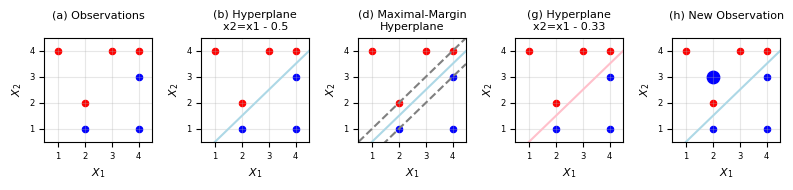

In [16]:
red_x1 = [3, 2, 4, 1]; red_x2 = [4, 2, 4, 4]; blue_x1 = [2, 4, 4]; blue_x2 = [1, 3, 1] # seven obervations and two dimensions
fig, axes = plt.subplots(1, 5, figsize=(8, 2))                                         # Create plots side by side
for i in range(0,5):                                                                   # setup common plot features
    axes[i].scatter(red_x1, red_x2, color='red', label='Red', s=20)
    axes[i].scatter(blue_x1, blue_x2, color='blue', label='Blue', s=20)
    axes[i].set_xlabel('$X_1$', fontsize=8)
    axes[i].set_ylabel('$X_2$', fontsize=8)
    axes[i].set(xticks=range(1, 5), yticks=range(1, 5))
    axes[i].set(xlim=(0.5, 4.5), ylim=(0.5, 4.5))
    axes[i].grid(alpha=0.3)
    axes[i].tick_params(axis='both', labelsize=6)
axes[0].set_title('(a) Observations\n',fontsize=8)                                    # (a) Observations
axes[1].set_title('(b) Hyperplane\nx2=x1 - 0.5', fontsize=8)                          # (b) Maximal-margin hyperplane
x = np.linspace(0.5, 4.5, 100) # X2 = X1 - 0.5
axes[1].plot(x, x - 0.5,color='lightblue',label='Maximal-marginhyperplane')
axes[2].set_title('(d) Maximal-Margin\nHyperplane',fontsize=8)                        # (c) Margin Lines
axes[2].plot(x, x - 0.5,color='lightblue',label='Maximal-marginhyperplane')
axes[2].plot(x, x, color='gray', linestyle='--', label='Margins')
axes[2].plot(x, x - 1,color='gray',linestyle='--')
axes[3].set_title('(g) Hyperplane\nx2=x1 - 0.33',fontsize=8)                          # (g) Hyperplane
x = np.linspace(0, 5, 100) # X2 = X1 - 0.33
axes[3].plot(x, x - 0.5,color='pink',label='Maximal-marginhyperplane')
axes[4].set_title('(h) New Observation\n',fontsize=8)                                 # (h) New Observation
axes[4].scatter(2, 3, color='blue', label='Blue', s=80)
axes[4].plot(x, x - 0.5,color='lightblue',label='Maximal-marginhyperplane')
plt.tight_layout()
plt.show()